## Key Insights

- **Sales fell ~15% in 2023 and stayed flat in 2024.** Total sales were ₹27.14L in 2022, ₹23.19L in 2023 (-14.6%) and ₹23.74L in 2024 (+2.4%). The business has not recovered to its 2022 level.

- **Category margins are nearly identical.** Average margin ranges only from 22.2% (Books) to 22.8% (Clothing). Books lead in sales (₹15.2L) but not in margin, though the gap is too small to justify shifting strategy on its own.

- **Discounts did not change margin % or quantity sold.** Margin stayed between 21.8% and 23.0% at every discount level, and average quantity was flat (5.5 units at 0% vs 5.2 at 25%). Lower profit per discounted order comes from lower order value, not from margin erosion.

- **Central has the lowest return rate (18.4%); the other four regions sit between 21.2% and 22.8%.** About 1 in 5 orders is returned overall (21.2%), which is high for retail. Central is the only region worth studying for what it does differently.

- **West × Clothing is the strongest region-category cell (₹3.95L), while East × Clothing is the weakest (₹2.16L).** Clothing's performance varies a lot by region, so inventory and marketing should be planned region by region.

**Note:** This is a synthetic dataset, so small differences between groups may be random noise. Findings were cross-validated across Google Sheets, MySQL and pandas.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("/content/retail_orders.csv")
df.head()

,order_id,order_date,ship_date,customer_id,customer_name,segment,region,city,product_id,category,sub_category,product_name,quantity,unit_price,discount,sales,profit,ship_mode,payment_method,returned
0,ORD1000,2023-07-18,2023-07-20,CUST0280,Customer_45,Home Office,West,Mumbai,PROD0008,Electronics,Phones,Phones Product 6,4,217.91,0.00,871.64,250.03,Second Class,Debit Card,Yes
1,ORD1001,2023-02-12,2023-02-18,CUST0004,Customer_82,Home Office,West,Pune,PROD0072,Books,Fiction,Fiction Product 10,9,635.08,0.25,4286.79,1098.46,Second Class,Net Banking,No
2,ORD1002,2022-07-18,2022-07-21,CUST0275,Customer_64,Corporate,North,Jaipur,PROD0076,Electronics,Cameras,Cameras Product 41,6,909.55,0.00,5457.30,1666.69,First Class,Cash,No
3,ORD1003,2023-04-12,2023-04-19,CUST0195,Customer_143,Corporate,East,Bangalore,PROD0095,Electronics,Phones,Phones Product 23,5,1477.98,0.05,7020.40,2480.09,Second Class,Net Banking,No
4,ORD1004,2024-12-29,2025-01-04,CUST0286,Customer_113,Home Office,East,Mumbai,PROD0059,Books,Non-Fiction,Non-Fiction Product 3,4,253.47,0.20,811.10,117.19,First Class,UPI,No


In [3]:
# Step 3B: Data Quality Check
# Checking shape, data types, missing values, duplicates and summary stats

df.shape
df.info()
df.isnull().sum()
df.duplicated().sum()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        2000 non-null   object 
 1   order_date      2000 non-null   object 
 2   ship_date       2000 non-null   object 
 3   customer_id     2000 non-null   object 
 4   customer_name   2000 non-null   object 
 5   segment         2000 non-null   object 
 6   region          2000 non-null   object 
 7   city            2000 non-null   object 
 8   product_id      2000 non-null   object 
 9   category        2000 non-null   object 
 10  sub_category    2000 non-null   object 
 11  product_name    2000 non-null   object 
 12  quantity        2000 non-null   int64  
 13  unit_price      2000 non-null   float64
 14  discount        2000 non-null   float64
 15  sales           2000 non-null   float64
 16  profit          2000 non-null   float64
 17  ship_mode       2000 non-null   o

,quantity,unit_price,discount,sales,profit
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,5.482000,751.936570,0.096825,3703.278880,837.368725
std,2.875554,427.734897,0.092021,3116.927438,868.305425
min,1.000000,10.850000,0.000000,15.320000,1.820000
25%,3.000000,378.155000,0.000000,1163.740000,209.007500
50%,6.000000,736.450000,0.100000,2915.220000,534.095000
75%,8.000000,1119.127500,0.200000,5535.190000,1197.857500
max,10.000000,1499.170000,0.250000,14655.000000,5557.380000


In [4]:
# Step 3C: Data Cleaning & Feature Engineering
# Converts date columns and creates new analysis columns
# Business use: Enables time-based trends and margin analysis

df["order_date"] = pd.to_datetime(df["order_date"])
df["ship_date"] = pd.to_datetime(df["ship_date"])

df["order_year"] = df["order_date"].dt.year
df["order_month"] = df["order_date"].dt.month
df["profit_margin"] = df["profit"] / df["sales"] * 100
df["shipping_days"] = (df["ship_date"] - df["order_date"]).dt.days

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        2000 non-null   object        
 1   order_date      2000 non-null   datetime64[ns]
 2   ship_date       2000 non-null   datetime64[ns]
 3   customer_id     2000 non-null   object        
 4   customer_name   2000 non-null   object        
 5   segment         2000 non-null   object        
 6   region          2000 non-null   object        
 7   city            2000 non-null   object        
 8   product_id      2000 non-null   object        
 9   category        2000 non-null   object        
 10  sub_category    2000 non-null   object        
 11  product_name    2000 non-null   object        
 12  quantity        2000 non-null   int64         
 13  unit_price      2000 non-null   float64       
 14  discount        2000 non-null   float64       
 15  sale

In [5]:
# Check for duplicate rows
df.duplicated().sum()

np.int64(0)

In [6]:
# Step 3D-1: Regional Performance Summary
# Calculates orders, sales, profit and margin per region
# Business use: Python version of SQL Q20, used to cross-validate results

df1 = df.groupby("region").agg(
    total_orders = ("order_id","count"),
    total_sales = ("sales","sum"),
    total_profit = ("profit","sum"),
    avg_profit_margin = ("profit_margin","mean")
    ).round(2).sort_values("total_profit",ascending = False)

df1

,total_orders,total_sales,total_profit,avg_profit_margin
region,,,,
West,450,1735360.29,381710.81,22.03
North,390,1521738.96,362055.44,23.13
Central,396,1395924.87,321999.68,22.96
East,391,1382212.92,304878.12,21.75
South,373,1371320.72,304093.40,22.65


In [7]:
# Step 3D-2: Category Performance Summary
# Calculates total sales, profit and average margin per category
# Business use: Confirms the Books revenue vs profitability finding

df2 = df.groupby("category").agg(
   total_sales = ("sales","sum"),
   total_profit = ("profit","sum"),
   avg_profit_margin = ("profit_margin","mean")
).round(2).sort_values("total_sales",ascending=False)

df2

,total_sales,total_profit,avg_profit_margin
category,,,
Books,1524441.69,338364.40,22.23
Electronics,1516388.26,337206.87,22.42
Sports,1509468.37,340905.57,22.73
Home & Kitchen,1453689.03,327661.80,22.30
Clothing,1402570.41,330598.81,22.80


In [8]:
# Step 3D-3: Monthly Sales Trend
# Calculates total sales for each year and month
# Business use: Python version of SQL Q9, used later for the line chart

monthly_sales = df.groupby(["order_year","order_month"])["sales"].sum().round(2).reset_index()

monthly_sales


,order_year,order_month,sales
0,2022,1,209807.40
1,2022,2,248736.79
2,2022,3,202813.05
3,2022,4,247197.18
4,2022,5,223377.02
5,2022,6,213674.94
6,2022,7,262926.66
7,2022,8,164355.46
8,2022,9,179088.55
9,2022,10,222657.47


In [9]:
monthly_sales["period"] = pd.to_datetime(
    monthly_sales["order_year"].astype(str) + "-" +
    monthly_sales["order_month"].astype(str) + "-01"
)

monthly_sales

,order_year,order_month,sales,period
0,2022,1,209807.40,2022-01-01
1,2022,2,248736.79,2022-02-01
2,2022,3,202813.05,2022-03-01
3,2022,4,247197.18,2022-04-01
4,2022,5,223377.02,2022-05-01
5,2022,6,213674.94,2022-06-01
6,2022,7,262926.66,2022-07-01
7,2022,8,164355.46,2022-08-01
8,2022,9,179088.55,2022-09-01
9,2022,10,222657.47,2022-10-01


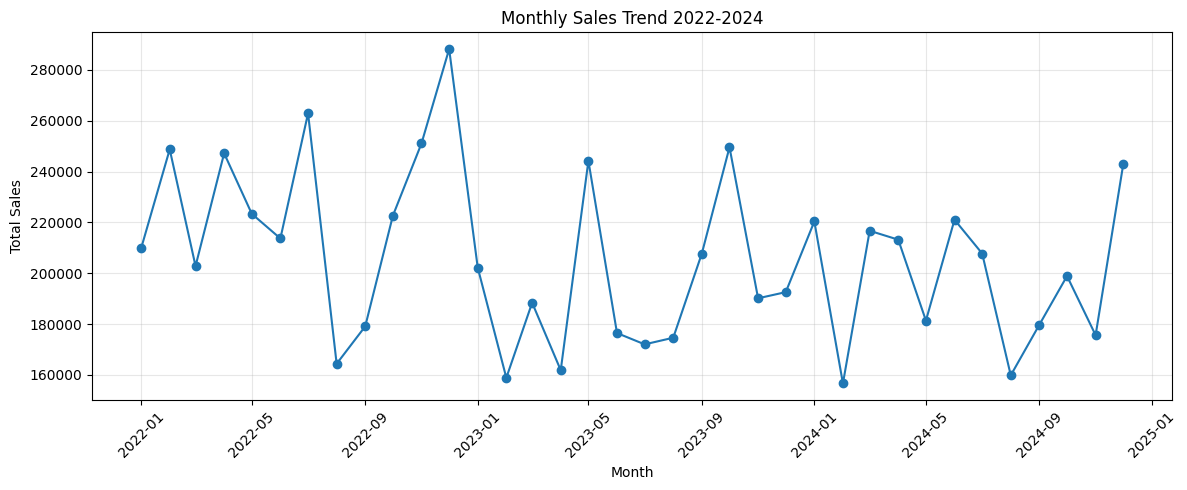

In [10]:
# Chart 1: Monthly Sales Trend 2022-2024
# Line chart of total sales per month
# Business use: Spot peak months (December) and slumps (February, August)

plt.figure(figsize=(12,5))
plt.plot(monthly_sales["period"],monthly_sales["sales"],marker="o")
plt.title("Monthly Sales Trend 2022-2024")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.grid(True,alpha=0.3)
plt.xticks(rotation=45)   # stops date labels overlapping
plt.tight_layout()        # trims extra white space
plt.show()

(21.5, 23.0)

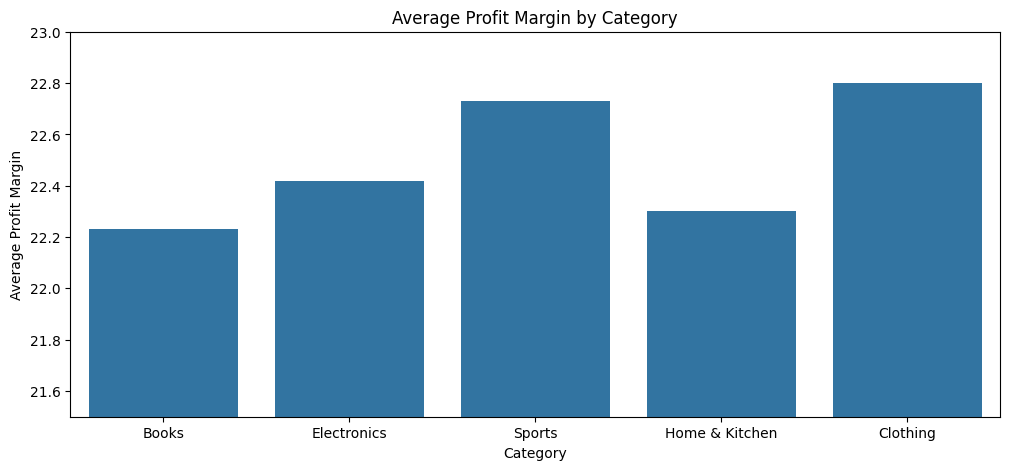

In [11]:
# Chart 2: Average Profit Margin by Category
# Bar chart comparing margin efficiency across categories
# Business use: Shows Books has the lowest margin despite the highest sales

plt.figure(figsize=(12,5))
sns.barplot(data=df2.reset_index(), x="category", y="avg_profit_margin")
plt.title("Average Profit Margin by Category")
plt.xlabel("Category")
plt.ylabel("Average Profit Margin")
plt.ylim(21.5,23)

In [19]:
# Chart 3: Discount Level vs Average Profit Margin
# Tests whether higher discounts actually reduce margin % (not just sales)
# Business use: Separates the mechanical effect of discounts from real margin erosion

discount_df = df.groupby("discount").agg(
    avg_profit_margin = ("profit_margin","mean"),
    avg_qty = ("quantity","mean")).round(2).reset_index()

discount_df

,discount,avg_profit_margin,avg_qty
0,0.00,22.49,5.50
1,0.05,21.95,5.61
2,0.10,22.99,5.63
3,0.15,21.80,5.49
4,0.20,22.76,5.46
5,0.25,22.92,5.18


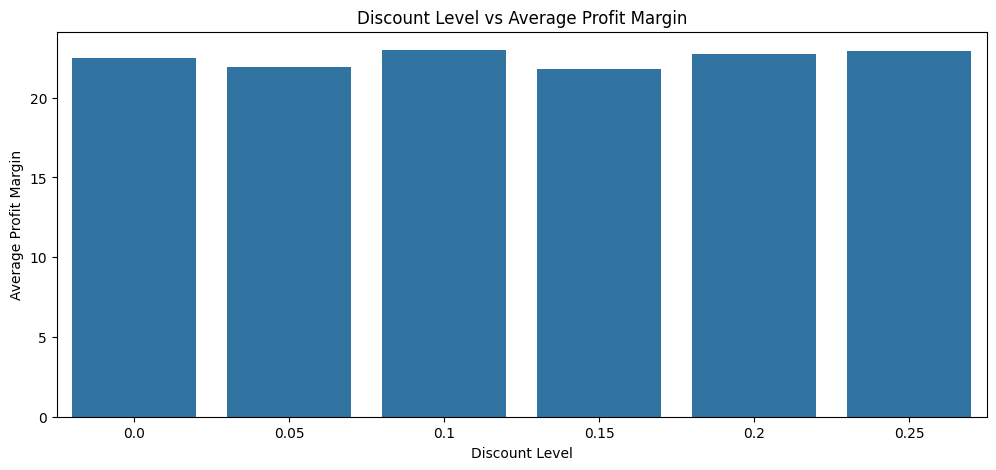

In [27]:
# Chart 3: Discount Level vs Average Profit Margin

plt.figure(figsize=(12,5))
sns.barplot(data=discount_df, x="discount", y="avg_profit_margin")
plt.title("Discount Level vs Average Profit Margin")
plt.xlabel("Discount Level")
plt.ylabel("Average Profit Margin")
plt.show()

In [20]:
# Chart 4: Return Rate by Region
# Bar chart of the % of orders returned in each region
# Business use: Python version of the Q20 return rate, shows which regions need attention

# Step: Return rate per region
df["is_returned"] = df["returned"] == "Yes"

return_df = (
    (df.groupby("region")["is_returned"].mean() * 100)
    .round(2)
    .sort_values(ascending=False)
    .reset_index()
    .rename(columns={"is_returned": "return_rate"})
)

return_df

,region,return_rate
0,North,22.82
1,East,21.99
2,West,21.56
3,South,21.18
4,Central,18.43


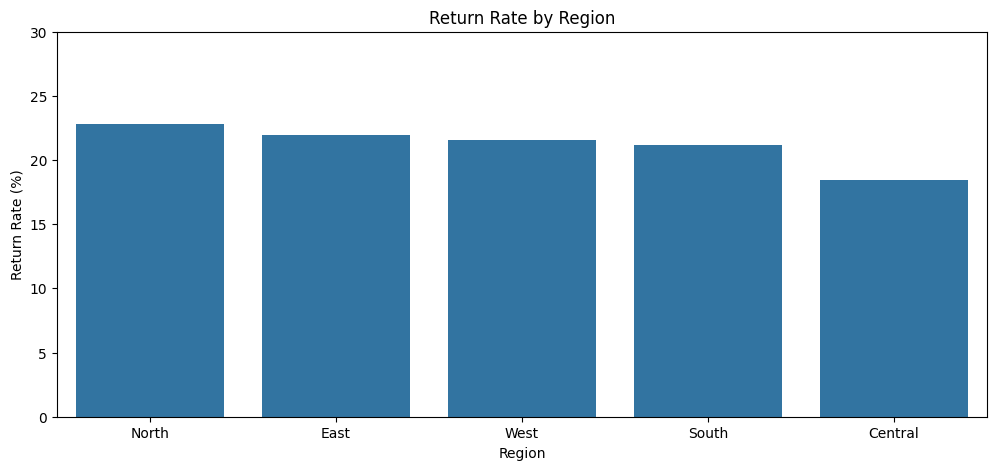

In [26]:
# Chart 4: Return Rate by Region

plt.figure(figsize=(12,5))
sns.barplot(data=return_df, x="region", y="return_rate")
plt.title("Return Rate by Region")
plt.xlabel("Region")
plt.ylabel("Return Rate (%)")
plt.ylim(0,30)
plt.show()

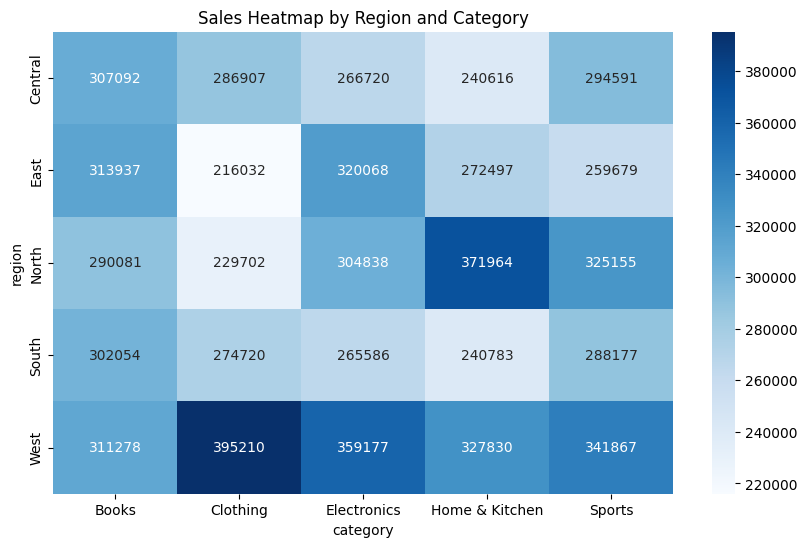

In [25]:
# Chart 5: Sales Heatmap by Region and Category
# Heatmap of total sales for every region-category combination
# Business use: Visual version of SQL Q7/Q19, shows where each category sells best

# Creating a Heatmap Data Frame
heat_df = df.pivot_table(
    index = "region",
    columns = "category",
    values = "sales",
    aggfunc = "sum"
)

# Chart : Sales Heatmap by Region and Category
plt.figure(figsize=(10,6))
sns.heatmap(heat_df,annot=True,fmt=".0f",cmap="Blues")
plt.title("Sales Heatmap by Region and Category")
plt.show()